In [45]:
import pandas as pd

In [46]:
test = pd.read_csv('aug_test.csv')
test.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
0,32403,city_41,0.827,Male,Has relevent experience,Full time course,Graduate,STEM,9,<10,NaN,1,21
1,9858,city_103,0.920,Female,Has relevent experience,no_enrollment,Graduate,STEM,5,NaN,Pvt Ltd,1,98
2,31806,city_21,0.624,Male,No relevent experience,no_enrollment,High School,NaN,<1,NaN,Pvt Ltd,never,15
3,27385,city_13,0.827,Male,Has relevent experience,no_enrollment,Masters,STEM,11,10/49,Pvt Ltd,1,39
4,27724,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,10000+,Pvt Ltd,>4,72


In [47]:
train = pd.read_csv('aug_train.csv')
train.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [48]:
#ringkasan info dari dataset
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

In [49]:
#statistik deskriptif dari dataset
train.describe(include="all")

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
count,19158.000000,19158,19158.000000,14650,19158,18772,18698,16345,19093,13220,13018,18735,19158.000000,19158.000000
unique,NaN,123,NaN,3,2,3,5,6,22,8,6,6,NaN,NaN
top,NaN,city_103,NaN,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,NaN,NaN
freq,NaN,4355,NaN,13221,13792,13817,11598,14492,3286,3083,9817,8040,NaN,NaN
mean,16875.358179,NaN,0.828848,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.366896,0.249348
std,9616.292592,NaN,0.123362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.058462,0.432647
min,1.000000,NaN,0.448000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000
25%,8554.250000,NaN,0.740000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000,0.000000
50%,16982.500000,NaN,0.903000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.000000,0.000000
75%,25169.750000,NaN,0.920000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,88.000000,0.000000


In [50]:
# jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

gender                 4508
enrolled_university     386
education_level         460
major_discipline       2813
experience               65
company_size           5938
company_type           6140
last_new_job            423
dtype: int64

In [51]:
#mengatasi missing value
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [52]:
    # mengisi nilai yang hilang dengan median untuk kolom numerik
    numeric_features = train[less].select_dtypes(include=['number']).columns
    train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [53]:
# mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [54]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [55]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

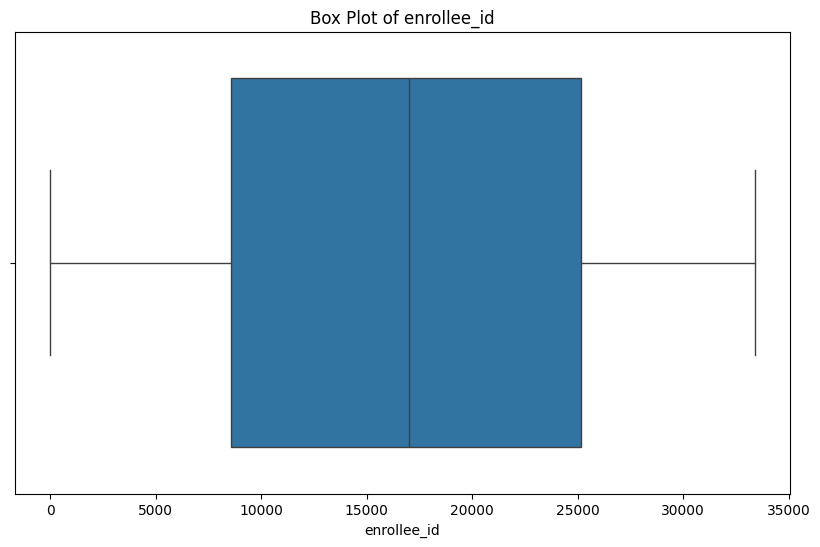

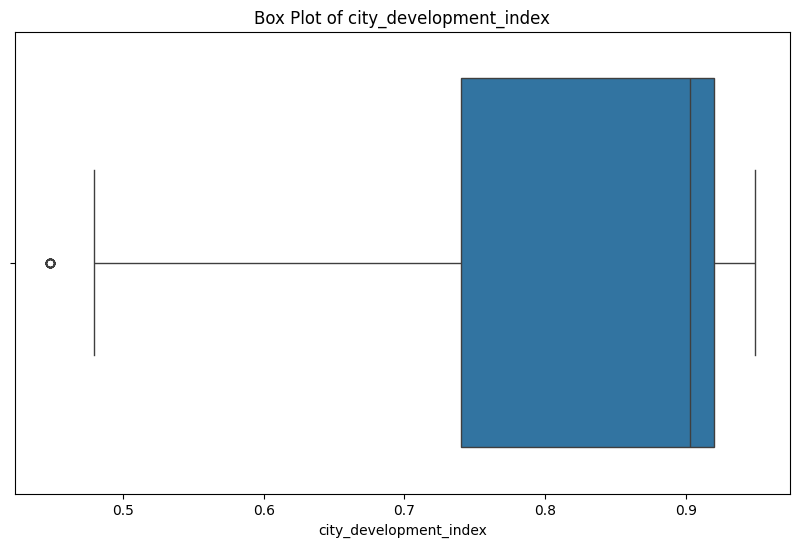

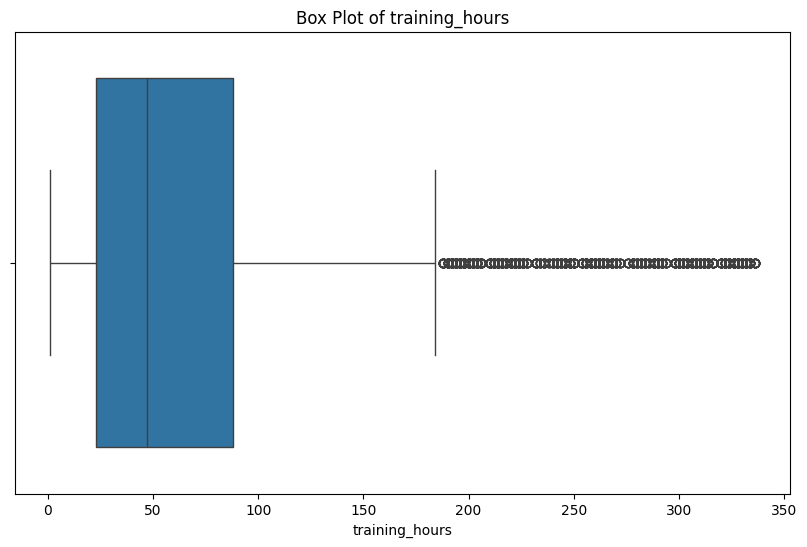

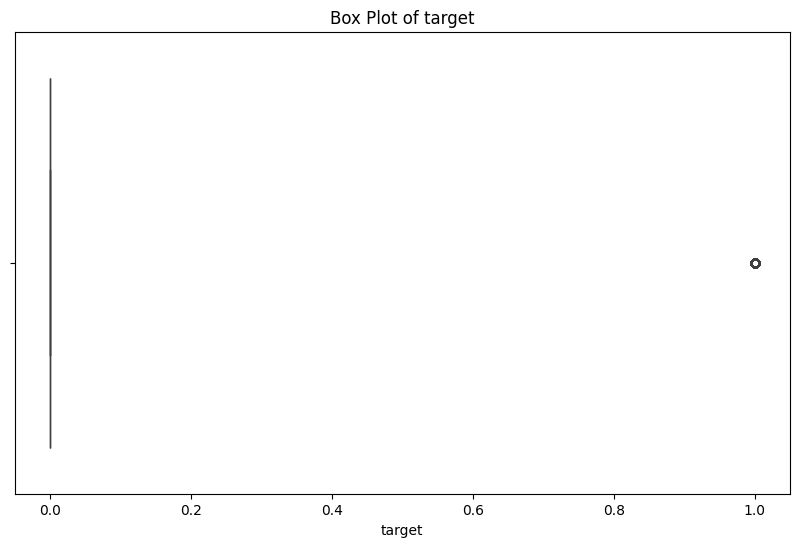

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
     plt.figure(figsize=(10, 6))
     sns.boxplot(x=df[feature])
     plt.title(f'Box Plot of {feature}')
     plt.show()

In [57]:
#mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [58]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [59]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [60]:
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

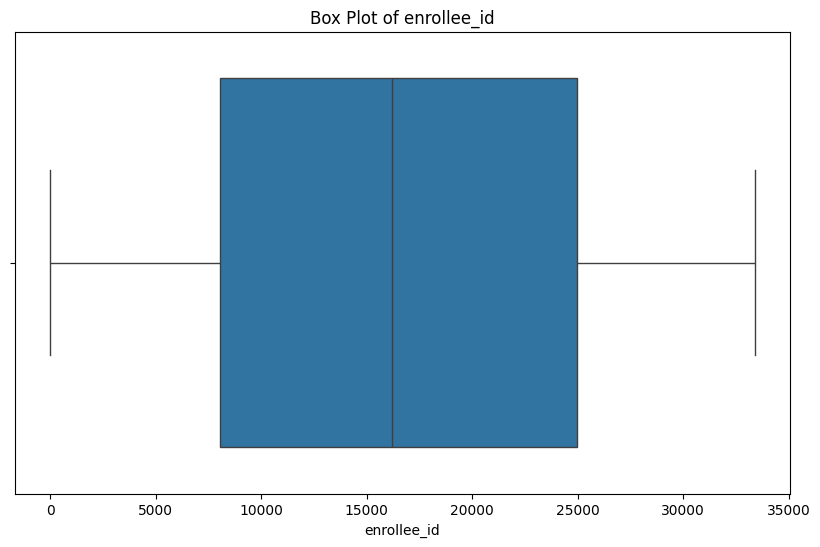

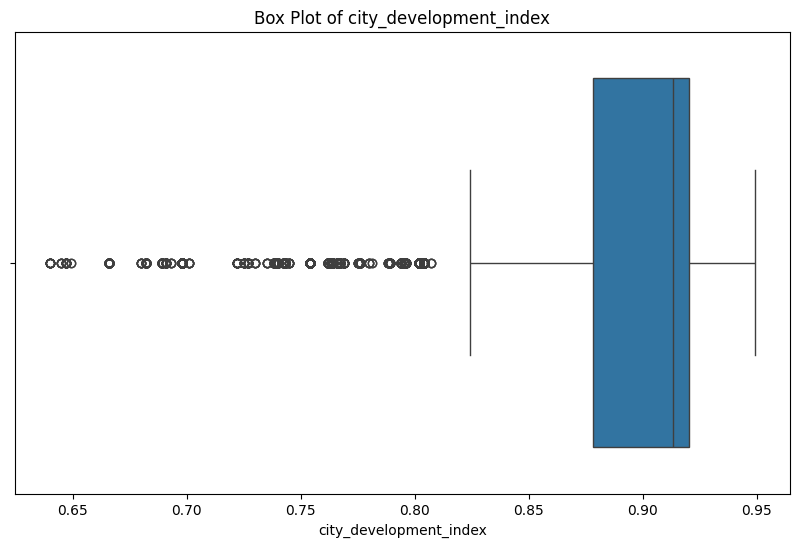

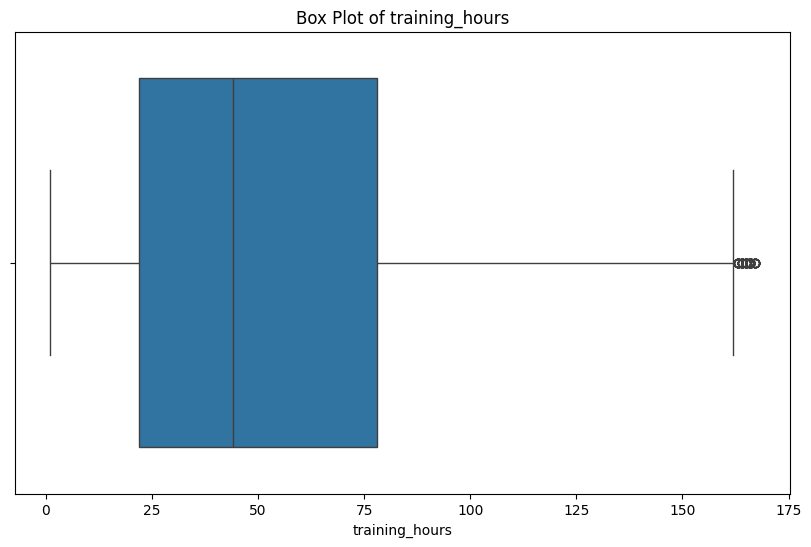

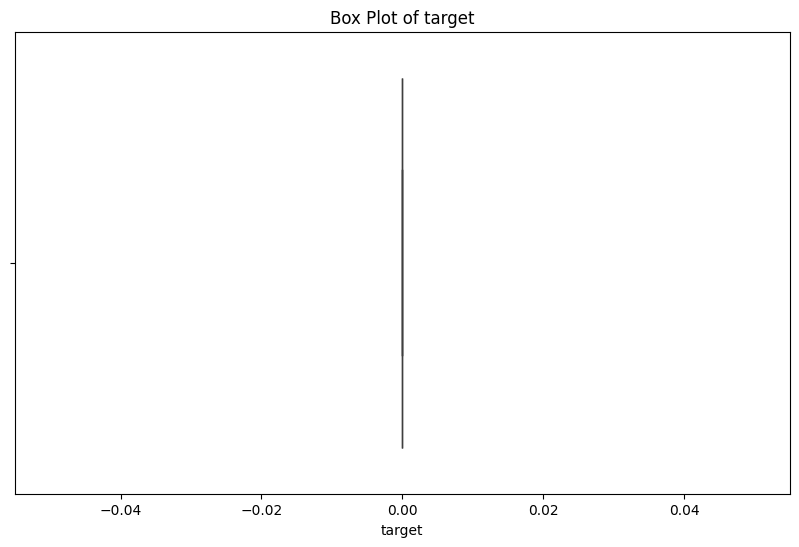

In [61]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

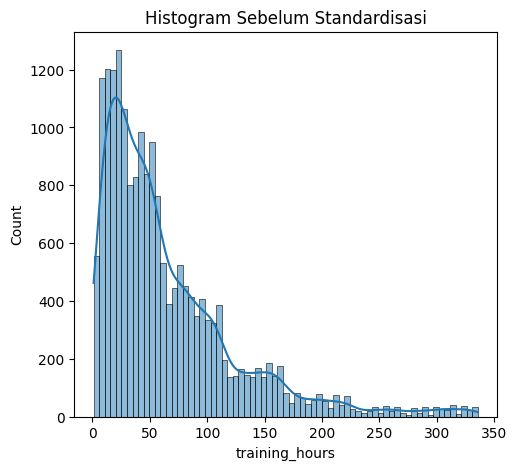

In [63]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[2]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

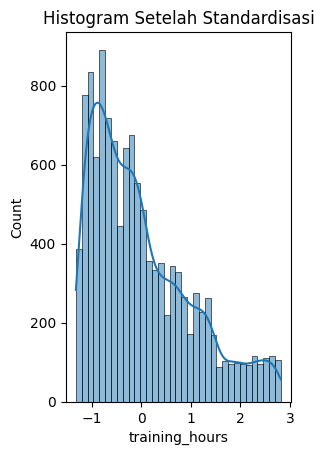

In [64]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[2]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [65]:
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [enrollee_id, city_development_index, training_hours, target, city, relevent_experience, enrolled_university, education_level, experience, last_new_job]
Index: []


In [66]:
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
       enrollee_id  city_development_index  training_hours  target      city  \
1         1.370497               -1.486662       -0.171335     0.0   city_40   
4        -1.628100               -1.615402       -1.142310     0.0  city_162   
6         1.275666                0.573173       -0.743961     0.0  city_160   
9        -1.624695                0.573173        1.720821     0.0  city_103   
11        0.764566                0.573173        1.347369     0.0  city_103   
...            ...                     ...             ...     ...       ...   
19151    -0.522007               -2.731146        0.152323     0.0  city_149   
19152     1.373490                0.573173       -0.719064     0.0  city_103   
19155     0.839172                0.573173       -0.246025     0.0  city_103   
19156    -1.102863               -1.114748        1.073504     0.0   city_65   
19157     0.762605               -0.356614        1.820408     0.0   city_67   

 

In [67]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,city,relevent_experience,enrolled_university,education_level,experience,last_new_job
1,city_40,No relevent experience,no_enrollment,Graduate,15,>4
4,city_162,Has relevent experience,no_enrollment,Masters,>20,4
6,city_160,Has relevent experience,no_enrollment,High School,5,1
9,city_103,Has relevent experience,no_enrollment,Graduate,17,>4
11,city_103,Has relevent experience,no_enrollment,Graduate,5,1
...,...,...,...,...,...,...
19151,city_149,No relevent experience,Full time course,Graduate,2,1
19152,city_103,Has relevent experience,no_enrollment,Graduate,7,1
19155,city_103,Has relevent experience,no_enrollment,Graduate,>20,4
19156,city_65,Has relevent experience,no_enrollment,High School,<1,2


In [68]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,enrollee_id,city_development_index,training_hours,target,city_city_1,city_city_10,city_city_100,city_city_102,city_city_103,city_city_104,...,experience_8,experience_9,experience_<1,experience_>20,last_new_job_1,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never
1,1.370497,-1.486662,-0.171335,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,-1.628100,-1.615402,-1.142310,0.0,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
6,1.275666,0.573173,-0.743961,0.0,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
9,-1.624695,0.573173,1.720821,0.0,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
11,0.764566,0.573173,1.347369,0.0,False,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19151,-0.522007,-2.731146,0.152323,0.0,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
19152,1.373490,0.573173,-0.719064,0.0,False,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
19155,0.839172,0.573173,-0.246025,0.0,False,False,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
19156,-1.102863,-1.114748,1.073504,0.0,False,False,False,False,False,False,...,False,False,True,False,False,True,False,False,False,False


In [69]:
from sklearn.preprocessing import LabelEncoder
 # Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,enrollee_id,city_development_index,training_hours,target,city,relevent_experience,enrolled_university,education_level,experience,last_new_job
1,1.370497,-1.486662,-0.171335,0.0,64,1,2,0,6,4
4,-1.628100,-1.615402,-1.142310,0.0,41,0,2,2,21,3
6,1.275666,0.573173,-0.743961,0.0,40,0,2,1,15,0
9,-1.624695,0.573173,1.720821,0.0,4,0,2,0,8,4
11,0.764566,0.573173,1.347369,0.0,4,0,2,0,15,0
...,...,...,...,...,...,...,...,...,...,...
19151,-0.522007,-2.731146,0.152323,0.0,33,1,0,0,11,0
19152,1.373490,0.573173,-0.719064,0.0,4,0,2,0,17,0
19155,0.839172,0.573173,-0.246025,0.0,4,0,2,0,21,3
19156,-1.102863,-1.114748,1.073504,0.0,78,0,2,1,20,1


In [70]:
df_lencoder.head()

,enrollee_id,city_development_index,training_hours,target,city,relevent_experience,enrolled_university,education_level,experience,last_new_job
1,1.370497,-1.486662,-0.171335,0.0,64,1,2,0,6,4
4,-1.628100,-1.615402,-1.142310,0.0,41,0,2,2,21,3
6,1.275666,0.573173,-0.743961,0.0,40,0,2,1,15,0
9,-1.624695,0.573173,1.720821,0.0,4,0,2,0,8,4
11,0.764566,0.573173,1.347369,0.0,4,0,2,0,15,0


In [71]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
    }).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


<function matplotlib.pyplot.show(close=None, block=None)>

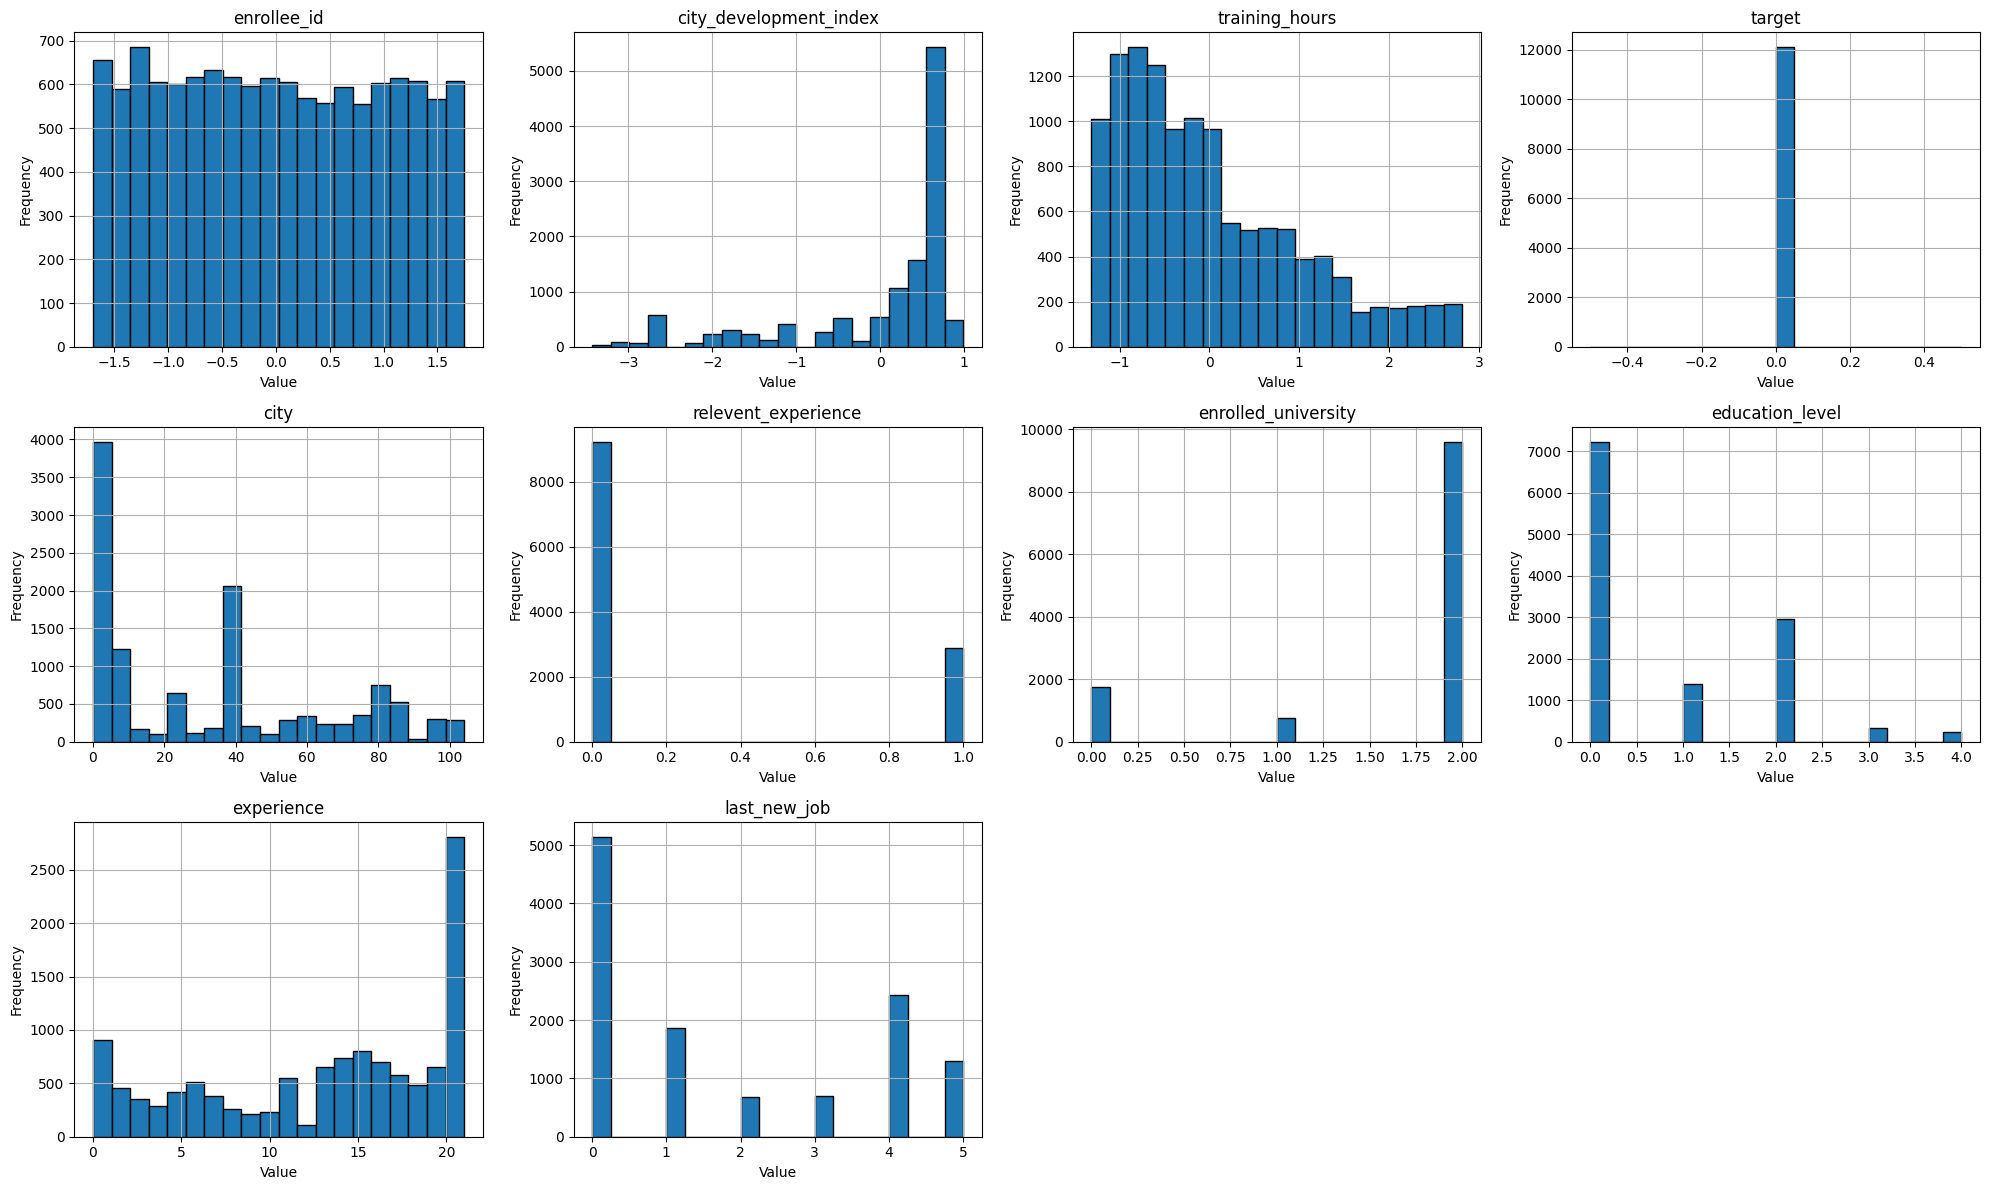

In [72]:
num_vars = df_lencoder.shape[1]

n_cols = 4 
n_rows = -(-num_vars // n_cols) 


fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show

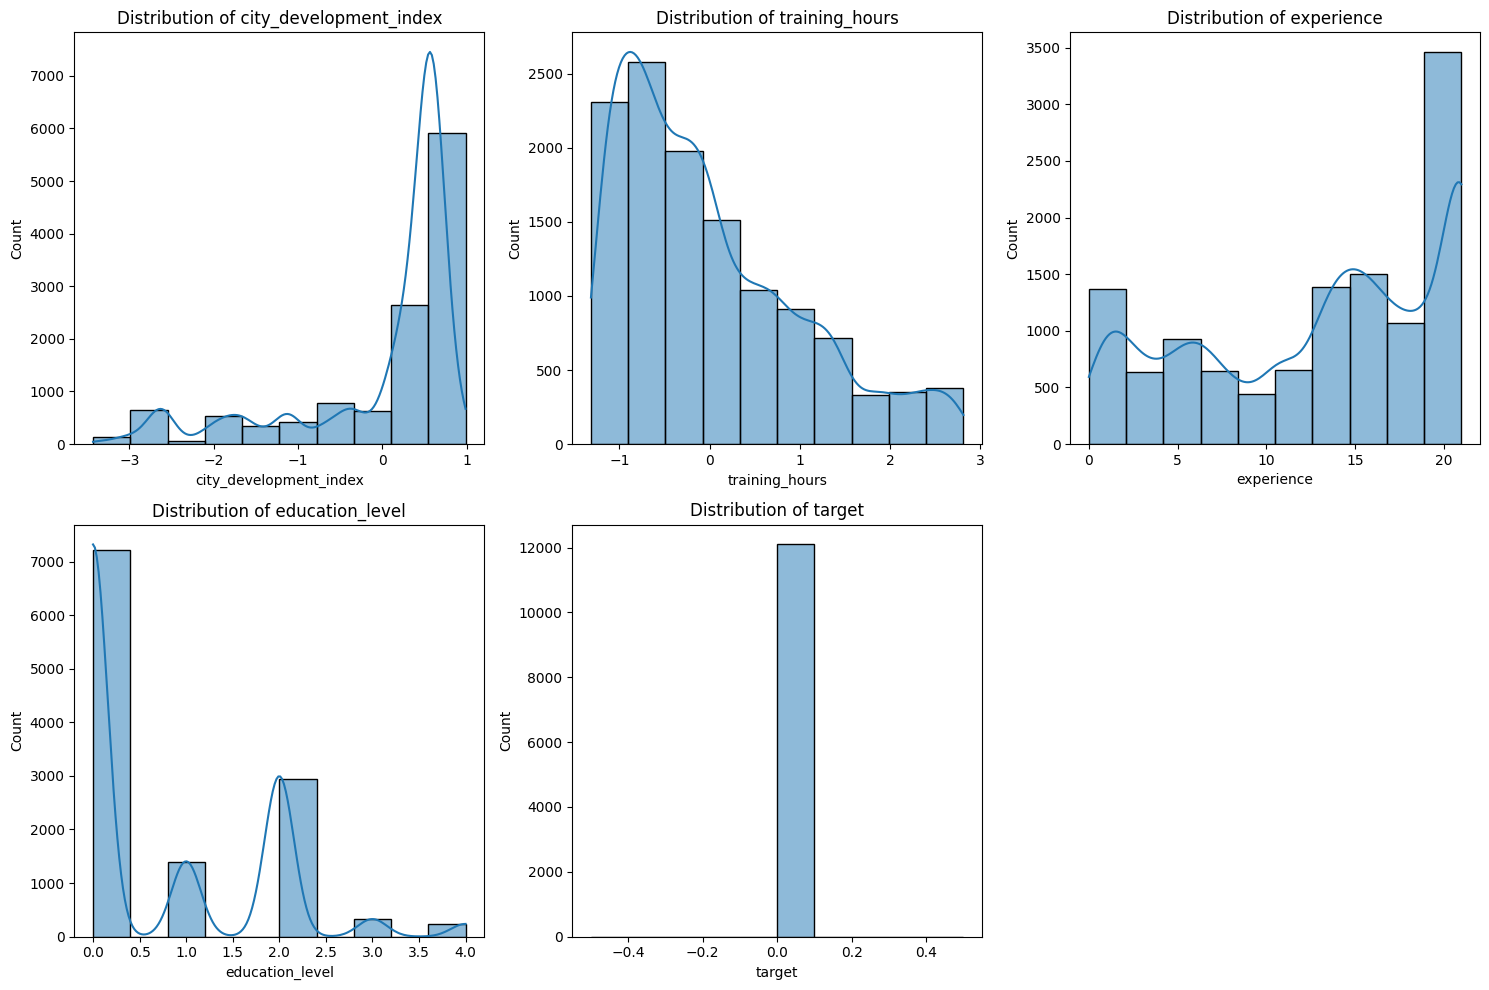

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = ['city_development_index', 'training_hours', 'experience',
                   'education_level', 'company_size', 'target']
columns_to_plot = [c for c in columns_to_plot if c in df_lencoder.columns]

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=10)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

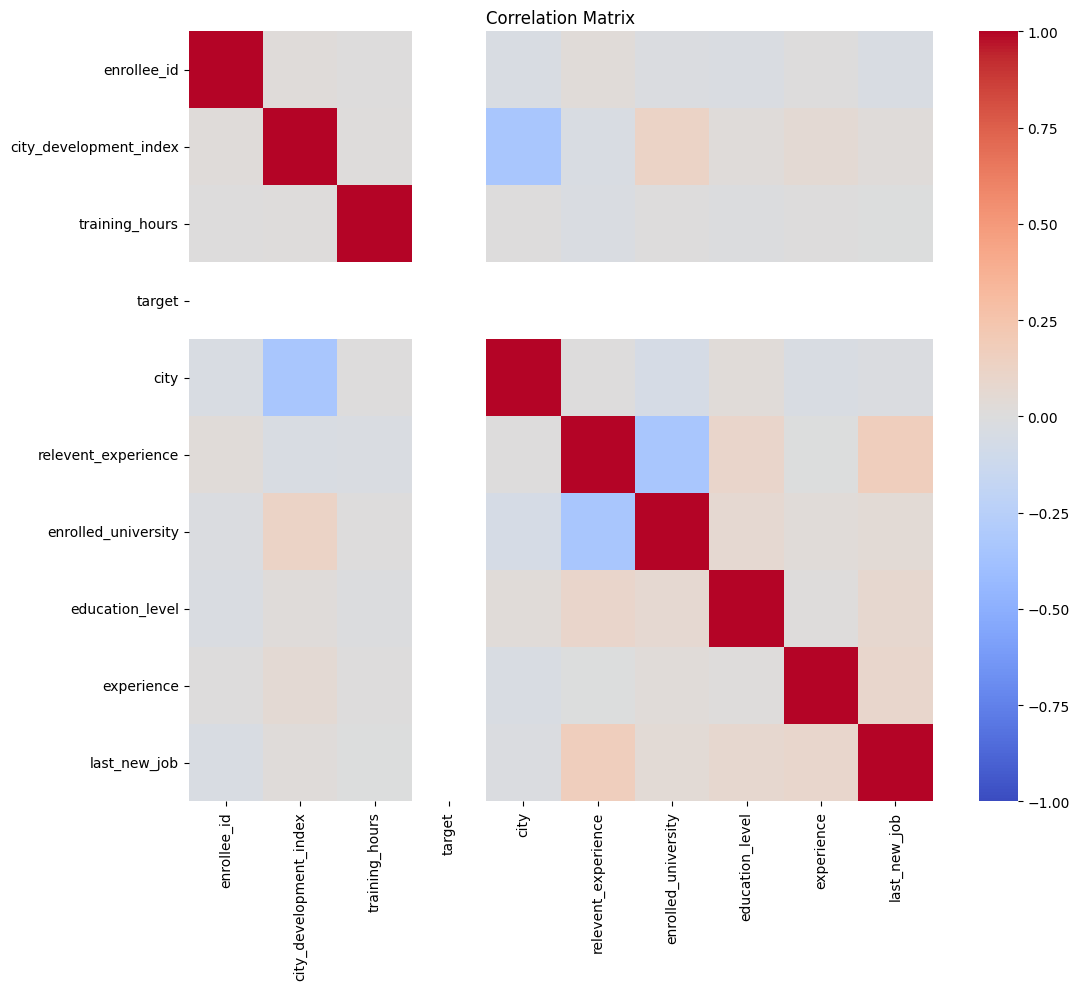

In [74]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()



In [75]:
df = pd.read_csv('aug_train.csv')
print(df.shape)                  # harus (19158, 14)
print(df['target'].unique())     # harus [1. 0.]

df_lencoder = df.copy()
for col in df_lencoder.select_dtypes(exclude='number').columns:
    df_lencoder[col] = LabelEncoder().fit_transform(df_lencoder[col].astype(str))

print(df_lencoder.shape, df_lencoder['target'].unique())

(19158, 14)
[1. 0.]
(19158, 14) [1. 0.]


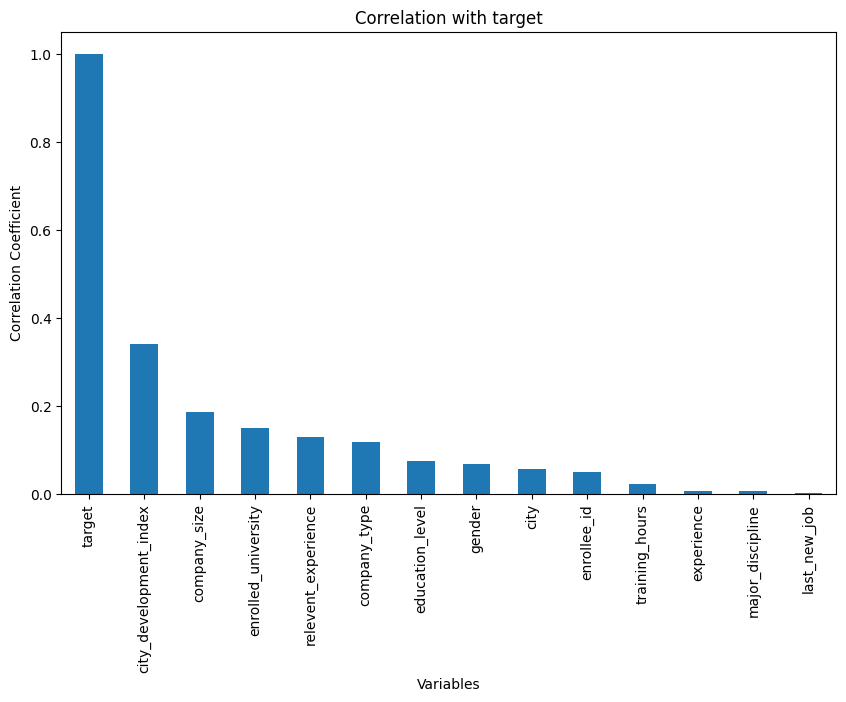

In [76]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['target']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with target')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [77]:
import sklearn

In [78]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['target']) 
y = df_lencoder['target'] 

In [79]:
from sklearn.model_selection import train_test_split

#membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [80]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  19158
Jumlah data latih:  15326
Jumlah data test:  3832


In [81]:
#melatih model 1 dengan algoritma Least Angle
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

#melatih model 2 dengan algoritma Linear regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [82]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
    }
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results



,MAE,MSE,R2
Lars,0.372417,0.185469,0.003864


In [83]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
Lars,0.372417,0.185469,0.003864
Linear Regression,0.312582,0.155192,0.166479


In [84]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.372417,0.185469,0.003864
Linear Regression,0.312582,0.155192,0.166479
GradientBoostingRegressor,0.281609,0.139597,0.250236


In [85]:
import joblib
# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']